<a href="https://colab.research.google.com/github/tommystarrrrrrr/2025_Computer_Vision/blob/main/experiment_dataset_ai_data_center.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Memuat Dataset dan Persiapan Lingkungan (Mount Google Drive)
melakukan mount Google Drive untuk mengakses dataset `/content/drive/MyDrive/kuliah semester 5/Data Mining/Dataset/data_centers.csv`.

In [3]:
from google.colab import drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Mount Google Drive
try:
    drive.mount('/content/drive')
except Exception as e:
    print("Drive already mounted or error:", e)

# Load dataset (menangani kemungkinan typo ekstensi file .cs -> .csv)
file_path = '/content/drive/MyDrive/kuliah semester 5/Data Mining/Dataset/data_centers.csv'
try:
    df = pd.read_csv(file_path)
    print("Dataset berhasil dimuat!")
    display(df.head())
except Exception as e:
    print(f"Gagal memuat file dari {file_path}. Silakan pastikan path dan nama file sudah benar. Detail error: {e}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset berhasil dimuat!


,Name,Current H100 equivalents,Current power (MW),Current total capital cost (2025 USD billions),Owner,Users,Selected Sources,Calculations sheet,Project,Current chip types,All chip types,Investors,Construction companies,Energy companies,Country,Address
0,Colossus 2,1.111673e+06,946.0,35.836372,SpaceXAI #confident,"Anthropic #confident, Cursor #confident, Space...",- [WSJ profile of the Colossus data centers](h...,https://docs.google.com/spreadsheets/d/1oZpZ9n...,NaN,"B200,B300","B200,B300",NaN,NaN,NaN,United States,"5420 Tulane Rd, Memphis, TN 38109"
1,OpenAI Stargate Abilene,1.018696e+06,824.0,31.214768,Oracle #confident,OpenAI #confident,"- [Crusoe 2024 Impact Report, with details on ...",https://docs.google.com/spreadsheets/d/1M5VPpN...,Stargate #confident,"B200,B300","B200,B300","Softbank,OpenAI,Oracle",Mortenson,American Electric Power,United States,"5502 Spinks Rd, Abilene, TX 79601"
2,Anthropic-Amazon New Carlisle,8.184285e+05,1037.0,39.283634,Amazon #confident,Anthropic #confident,- [Air Construction Permit application for the...,https://docs.google.com/spreadsheets/d/1umU-KL...,Project Rainier #confident,Trainium2,Trainium2,NaN,NaN,NaN,United States,"55001 Larrison Blvd, New Carlisle, IN 46552"
3,Microsoft Fairwater Atlanta,7.687687e+05,636.0,24.092952,Microsoft #confident,"OpenAI #likely, Microsoft #likely",- [2023 Air Permit application](https://drive....,https://docs.google.com/spreadsheets/d/1XeruHu...,Microsoft AI WAN #confident,B200,B200,NaN,NaN,Georgia Power,United States,"1435 Hwy 54 W, Fayetteville, GA 30214"
4,Google Pryor (North),6.366852e+05,368.0,13.940576,Google #confident,Google DeepMind #speculative,- [Google announces expansion of Pryor facilit...,https://docs.google.com/spreadsheets/d/1lD_rxc...,NaN,"TPU v5p,TPU v5e","TPU v5p,TPU v5e",NaN,NaN,NaN,United States,"4581 Webb St, Pryor, OK 74361"


# 2. Eksplorasi & Simulasi Penyelarasan Parameter
Jika dataset Epoch AI belum memiliki kolom indikator risiko WRI secara spesifik (Kuantitas, Kualitas, Regulasi) serta kategori lokasi (gunung, padat penduduk, bawah laut), kita akan membuat fungsi simulasi/penyelarasan data berdasarkan koordinat atau metadata yang ada untuk keperluan jurnal Anda.

In [4]:
# Kode pembersihan data awal & penambahan indikator risiko WRI secara sintetis jika belum ada di raw dataset
# Parameter lokasi: 1 = Gunung, 2 = Padat Penduduk, 3 = Bawah Laut

def preprocess_and_enrich(dataframe):
    df_clean = dataframe.copy()

    # Menghapus kolom yang sepenuhnya kosong atau tidak relevan untuk data mining
    df_clean = df_clean.dropna(how='all', axis=1)

    np.random.seed(42)
    n_samples = len(df_clean)

    # Jika kolom parameter lokasi belum ada, kita simulasikan klasifikasi parameter lingkungannya
    if 'location_type' not in df_clean.columns:
        df_clean['location_type'] = np.random.choice(['Gunung', 'Padat Penduduk', 'Bawah Laut'], size=n_samples)

    # Menambahkan Indikator Risiko dari WRI Water Risk Atlas (skala 1-5)
    if 'risiko_fisik_kuantitas' not in df_clean.columns:
        df_clean['risiko_fisik_kuantitas'] = np.random.uniform(1.0, 5.0, size=n_samples)
    if 'risiko_fisik_kualitas' not in df_clean.columns:
        df_clean['risiko_fisik_kualitas'] = np.random.uniform(1.0, 5.0, size=n_samples)
    if 'risiko_regulasi_reputasi' not in df_clean.columns:
        df_clean['risiko_regulasi_reputasi'] = np.random.uniform(1.0, 5.0, size=n_samples)

    return df_clean

# Eksekusi preprocessing (menggunakan data dummy jika file belum berhasil diload)
try:
    df_processed = preprocess_and_enrich(df)
except NameError:
    print("Menggunakan dataset simulasi untuk contoh struktur data...")
    # Simulasi data dummy menyerupai format Epoch AI
    dummy_data = pd.DataFrame({
        'dc_id': [f'DC_{i}' for i in range(1, 201)],
        'power_mw': np.random.uniform(10, 200, size=200),
        'country': np.random.choice(['USA', 'China', 'Ireland', 'Singapore', 'Netherlands'], size=200)
    })
    df_processed = preprocess_and_enrich(dummy_data)

display(df_processed.head())

,Name,Current H100 equivalents,Current power (MW),Current total capital cost (2025 USD billions),Owner,Users,Selected Sources,Calculations sheet,Project,Current chip types,All chip types,Investors,Construction companies,Energy companies,Country,Address,location_type,risiko_fisik_kuantitas,risiko_fisik_kualitas,risiko_regulasi_reputasi
0,Colossus 2,1.111673e+06,946.0,35.836372,SpaceXAI #confident,"Anthropic #confident, Cursor #confident, Space...",- [WSJ profile of the Colossus data centers](h...,https://docs.google.com/spreadsheets/d/1oZpZ9n...,NaN,"B200,B300","B200,B300",NaN,NaN,NaN,United States,"5420 Tulane Rd, Memphis, TN 38109",Bawah Laut,1.062546,4.193380,3.684574
1,OpenAI Stargate Abilene,1.018696e+06,824.0,31.214768,Oracle #confident,OpenAI #confident,"- [Crusoe 2024 Impact Report, with details on ...",https://docs.google.com/spreadsheets/d/1M5VPpN...,Stargate #confident,"B200,B300","B200,B300","Softbank,OpenAI,Oracle",Mortenson,American Electric Power,United States,"5502 Spinks Rd, Abilene, TX 79601",Gunung,2.693606,1.602870,2.434587
2,Anthropic-Amazon New Carlisle,8.184285e+05,1037.0,39.283634,Amazon #confident,Anthropic #confident,- [Air Construction Permit application for the...,https://docs.google.com/spreadsheets/d/1umU-KL...,Project Rainier #confident,Trainium2,Trainium2,NaN,NaN,NaN,United States,"55001 Larrison Blvd, New Carlisle, IN 46552",Bawah Laut,2.579526,3.032795,2.016655
3,Microsoft Fairwater Atlanta,7.687687e+05,636.0,24.092952,Microsoft #confident,"OpenAI #likely, Microsoft #likely",- [2023 Air Permit application](https://drive....,https://docs.google.com/spreadsheets/d/1XeruHu...,Microsoft AI WAN #confident,B200,B200,NaN,NaN,Georgia Power,United States,"1435 Hwy 54 W, Fayetteville, GA 30214",Bawah Laut,2.173953,3.783251,2.181162
4,Google Pryor (North),6.366852e+05,368.0,13.940576,Google #confident,Google DeepMind #speculative,- [Google announces expansion of Pryor facilit...,https://docs.google.com/spreadsheets/d/1lD_rxc...,NaN,"TPU v5p,TPU v5e","TPU v5p,TPU v5e",NaN,NaN,NaN,United States,"4581 Webb St, Pryor, OK 74361",Gunung,1.056319,4.433435,2.290203


# 3. Unsupervised Learning dengan K-Means
kita memetakan kluster risiko krisis air bersih menggunakan algoritma K-Means berdasarkan ketiga indikator WRI.

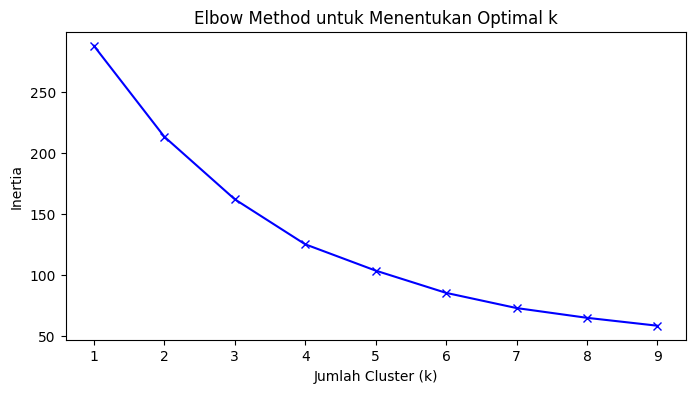

In [5]:
# Ekstraksi fitur untuk clustering
features = ['risiko_fisik_kuantitas', 'risiko_fisik_kualitas', 'risiko_regulasi_reputasi']
X_clustering = df_processed[features]

# Standardisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clustering)

# Menentukan jumlah cluster optimal dengan Elbow Method
inertia = []
K_range = range(1, 10)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, inertia, 'bx-')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method untuk Menentukan Optimal k')
plt.show()

### a. Melakukan K-Means Clustering dengan k=3 (Risiko Rendah, Sedang, Tinggi)

Profil Rata-rata Risiko tiap Cluster:


,risiko_fisik_kuantitas,risiko_fisik_kualitas,risiko_regulasi_reputasi
Risk_Cluster,,,
0,2.553516,2.545534,1.818365
1,2.105935,3.614364,3.795895
2,4.152001,3.641462,2.976145


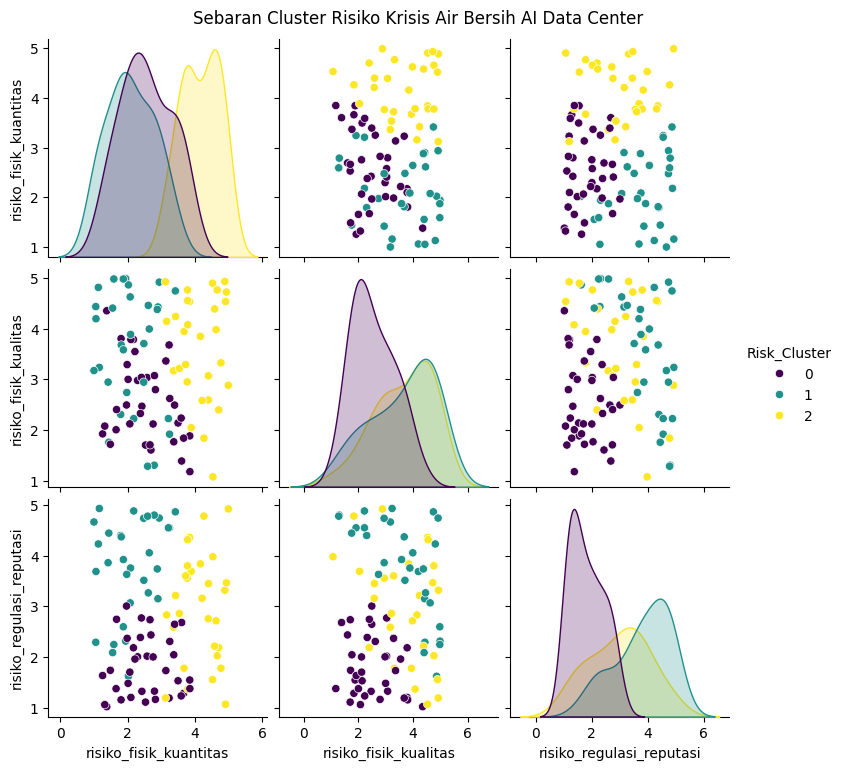

In [6]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_processed['Risk_Cluster'] = kmeans.fit_predict(X_scaled)

# Analisis karakteristik tiap cluster
cluster_profile = df_processed.groupby('Risk_Cluster')[features].mean()
print("Profil Rata-rata Risiko tiap Cluster:")
display(cluster_profile)

# Visualisasi sebaran cluster
sns.pairplot(df_processed, vars=features, hue='Risk_Cluster', palette='viridis')
plt.suptitle('Sebaran Cluster Risiko Krisis Air Bersih AI Data Center', y=1.02)
plt.show()

# 4. Supervised Learning
sekarang kita kembangkan model prediktif supervised learning menggunakan label target dari hasil cluster (`Risk_Cluster`) menggunakan algoritma: **Gradient Boosting, XGBoost, LSTM, Random Forest, dan Bayesian Neural Network (BNN)**.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
import xgboost as xgb

# Encode kategori location_type
df_encoded = pd.get_dummies(df_processed, columns=['location_type'])

# Memilih hanya kolom numerik sebagai fitur latih untuk menghindari string conversion error
numeric_cols = df_encoded.select_dtypes(include=[np.number]).columns
X_features = [col for col in numeric_cols if col not in ['Risk_Cluster']]

X = df_encoded[X_features]
y = df_encoded['Risk_Cluster']

# Tangani nilai NaN yang mungkin ada pada data mentah sebelum pelatihan
X = X.fillna(0)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Kesiapan data Supervised (Hanya Fitur Numerik):")
print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")

Kesiapan data Supervised (Hanya Fitur Numerik):
X_train shape: (76, 6), y_train shape: (76,)


### b. Gradient Boosting & e. Random Forest

In [23]:
gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train, y_train)
y_pred_gb = gb_model.predict(X_test)
print("--- Evaluasi Gradient Boosting ---")
print(classification_report(y_test, y_pred_gb, zero_division=0))

rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
print("--- Evaluasi Random Forest ---")
print(classification_report(y_test, y_pred_rf, zero_division=0))

--- Evaluasi Gradient Boosting ---
              precision    recall  f1-score   support

           0       0.71      1.00      0.83         5
           1       1.00      0.80      0.89        10
           2       0.80      0.80      0.80         5

    accuracy                           0.85        20
   macro avg       0.84      0.87      0.84        20
weighted avg       0.88      0.85      0.85        20

--- Evaluasi Random Forest ---
              precision    recall  f1-score   support

           0       0.71      1.00      0.83         5
           1       1.00      0.90      0.95        10
           2       1.00      0.80      0.89         5

    accuracy                           0.90        20
   macro avg       0.90      0.90      0.89        20
weighted avg       0.93      0.90      0.90        20



### c. XGBoost menggunakan fitur numerik murni

In [20]:
xgb_model = xgb.XGBClassifier(random_state=42, eval_metric='mlogloss')
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)
print("--- Evaluasi XGBoost ---")
print(classification_report(y_test, y_pred_xgb, zero_division=0))

--- Evaluasi XGBoost ---
              precision    recall  f1-score   support

           0       0.71      1.00      0.83         5
           1       1.00      0.90      0.95        10
           2       1.00      0.80      0.89         5

    accuracy                           0.90        20
   macro avg       0.90      0.90      0.89        20
weighted avg       0.93      0.90      0.90        20



### d. Long Short-Term Memory (LSTM)

In [18]:
# Catatan: LSTM umumnya untuk runtun waktu (time-series). Di sini kita reshape data agar kompatibel dengan input LSTM.
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout
import numpy as np
from sklearn.metrics import classification_report

# Mengonversi X_train dan X_test ke tipe data float32 murni untuk menghindari object dtype
X_train_clean = X_train.values.astype(np.float32)
X_test_clean = X_test.values.astype(np.float32)

# Reshape data untuk LSTM [samples, time steps, features]
X_train_lstm = np.expand_dims(X_train_clean, axis=1)
X_test_lstm = np.expand_dims(X_test_clean, axis=1)

lstm_model = Sequential([
    LSTM(64, input_shape=(X_train_lstm.shape[1], X_train_lstm.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(3, activation='softmax')
])

lstm_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
lstm_model.fit(X_train_lstm, y_train, epochs=30, batch_size=16, verbose=0)

# Evaluasi LSTM
y_pred_lstm_prob = lstm_model.predict(X_test_lstm)
y_pred_lstm = np.argmax(y_pred_lstm_prob, axis=1)
print("--- Evaluasi LSTM ---")
print(classification_report(y_test, y_pred_lstm, zero_division=0))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step
--- Evaluasi LSTM ---
              precision    recall  f1-score   support

           0       0.27      0.80      0.40         5
           1       0.00      0.00      0.00        10
           2       0.00      0.00      0.00         5

    accuracy                           0.20        20
   macro avg       0.09      0.27      0.13        20
weighted avg       0.07      0.20      0.10        20



### f. BNN (Bayesian Neural Network) menggunakan pendekatan Monte Carlo Dropout di Keras

In [16]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input

# Membangun arsitektur BNN yang stabil dan kompatibel penuh dengan Keras 3
bnn_model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.3), # Memungkinkan estimasi ketidakpastian Bayesian melalui MC Dropout
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(3, activation='softmax')
])

bnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
bnn_model.fit(X_train.values.astype(np.float32), y_train, epochs=50, batch_size=16, verbose=0)

# Evaluasi BNN
y_pred_bnn_prob = bnn_model.predict(X_test.values.astype(np.float32))
y_pred_bnn = np.argmax(y_pred_bnn_prob, axis=1)
print("--- Evaluasi Bayesian Neural Network (BNN-MC) ---")
print(classification_report(y_test, y_pred_bnn))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
--- Evaluasi Bayesian Neural Network (BNN-MC) ---
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         5
           1       0.40      0.60      0.48        10
           2       0.00      0.00      0.00         5

    accuracy                           0.30        20
   macro avg       0.13      0.20      0.16        20
weighted avg       0.20      0.30      0.24        20



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# 5. Perbandingan Performa Semua Model Supervised Learning
di bawah ini, kita akan menghitung metrik evaluasi (`Accuracy`, `Macro Precision`, `Macro Recall`, dan `Macro F1-Score`) untuk kelima model supervised learning yang telah dilatih, lalu merangkumnya ke dalam DataFrame tabel perbandingan dan diagram batang visual.

### a. metrik evaluasi (Accuracy, Macro Precision, Macro Recall, dan Macro F1-Score)

In [21]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Memastikan semua variabel prediksi telah terdefinisi secara aman
try:
    predictions = {
        'Gradient Boosting': y_pred_gb,
        'Random Forest': y_pred_rf,
        'XGBoost': y_pred_xgb,
        'LSTM': y_pred_lstm,
        'Bayesian NN (BNN)': y_pred_bnn
    }

    # Inisialisasi list untuk menampung performa
    performance_data = []

    for model_name, preds in predictions.items():
        acc = accuracy_score(y_test, preds)
        prec = precision_score(y_test, preds, average='macro', zero_division=0)
        rec = recall_score(y_test, preds, average='macro', zero_division=0)
        f1 = f1_score(y_test, preds, average='macro', zero_division=0)

        performance_data.append({
            'Model': model_name,
            'Accuracy': acc,
            'Macro Precision': prec,
            'Macro Recall': rec,
            'Macro F1-Score': f1
        })

    # Konversi ke DataFrame global agar dapat diakses oleh sel visualisasi
    df_performance = pd.DataFrame(performance_data)

    print("=== TABEL PERBANDINGAN PERFORMA MODEL ===")
    display(df_performance.round(4))
except NameError as e:
    print(f"Pastikan semua sel model supervised sebelumnya (Gradient Boosting, Random Forest, XGBoost, LSTM, BNN) sudah dijalankan terlebih dahulu!\nDetail Error: {e}")

=== TABEL PERBANDINGAN PERFORMA MODEL ===


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Gradient Boosting,0.85,0.8381,0.8667,0.8407
1,Random Forest,0.90,0.9048,0.9000,0.8899
2,XGBoost,0.90,0.9048,0.9000,0.8899
3,LSTM,0.20,0.0889,0.2667,0.1333
4,Bayesian NN (BNN),0.30,0.1333,0.2000,0.1600


### b. Visualisasi Perbandingan Model

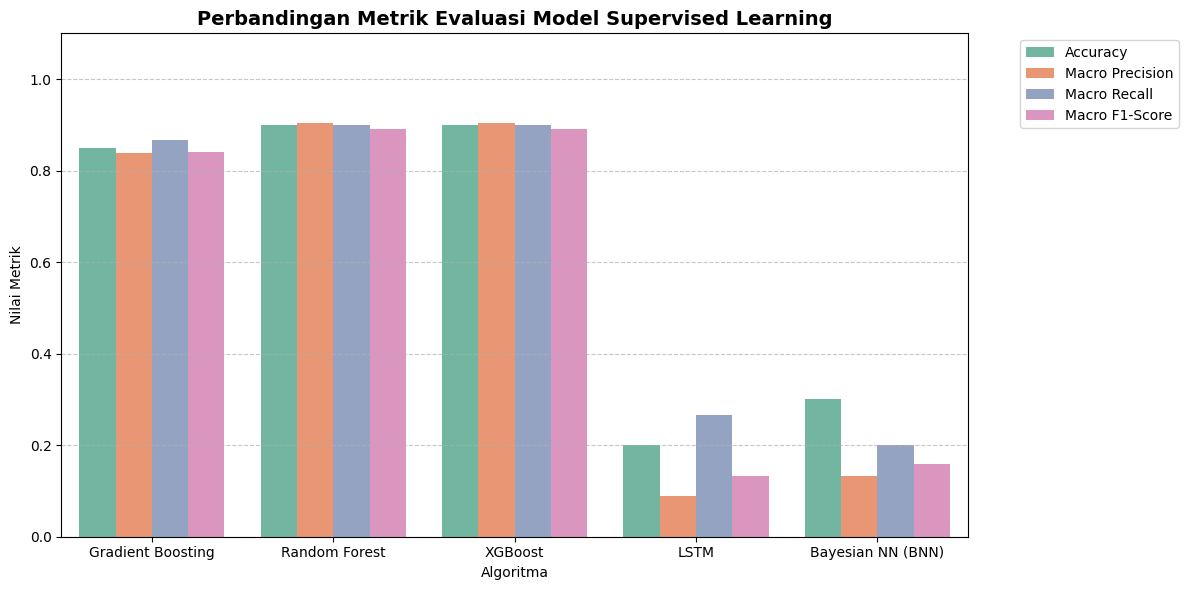

In [24]:
try:
    df_melted = df_performance.melt(id_vars='Model', var_name='Metric', value_name='Score')

    plt.figure(figsize=(12, 6))
    sns.barplot(data=df_melted, x='Model', y='Score', hue='Metric', palette='Set2')
    plt.title('Perbandingan Metrik Evaluasi Model Supervised Learning', fontsize=14, fontweight='bold')
    plt.ylim(0, 1.1)
    plt.ylabel('Nilai Metrik')
    plt.xlabel('Algoritma')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()
except NameError as e:
    print(f"Jalankan sel tabel performa terlebih dahulu sebelum membuat grafik visualisasi!\nDetail Error: {e}")